# Literature Review: Convolutional Neural Networks for Plant Disease Classification
## History, prior work, research gap, drawbacks and the state of the art

*COMP6001 - Computer Vision and Multimodal Machine Learning - Final Project*

## Section 1 - Purpose and Scope of the Review

The method chosen for this project is a **convolutional neural network (CNN) trained from scratch to classify leaf images into crop-disease classes**, compared against classical machine learning and transfer learning. This review places that choice in the context of existing research. It answers five questions:

1. **History** - where do CNNs come from, and how did they reach plant-disease diagnosis? (Section 2)
2. **Prior work** - what has already been done with CNNs on this task, and with what results? (Section 3)
3. **Research gap** - what is still unsolved or under-studied? (Section 4)
4. **Novelty** - what does this project add, stated honestly, compared with prior work? (Section 5)
5. **Drawbacks and state of the art** - what are the weaknesses of the chosen method, and what do the best current methods look like? (Sections 6 and 7)

The review covers work from the 1960s on the biological origins of CNNs to preprints from 2026 on vision-language models for plant disease. Plant-disease papers were selected because they use leaf images for crop-disease classification, the PlantVillage or PlantDoc datasets, or multimodal image-text data. Results quoted from other papers come from different data splits and protocols, so they are not directly comparable with each other; they are used to show trends, not to rank methods.

## Section 2 - History of the Method

### 2.1 Biological roots and early neural networks (1960s - 1990s)

The idea behind CNNs comes from neuroscience. Hubel and Wiesel (1962) recorded from cells in the cat visual cortex and described *receptive fields*: each cell responds only to a small region of the visual field, and simple cells that detect edges feed complex cells that tolerate small shifts. Fukushima (1980) turned this idea into the **Neocognitron**, a layered network that recognises patterns regardless of their position, with alternating feature-detecting and pooling layers, the structure that CNNs still use.

The step that made such networks trainable came with **backpropagation**. LeCun et al. (1989) trained a convolutional network with backpropagation to read handwritten zip-code digits, and LeCun et al. (1998) refined it into **LeNet-5** for document recognition. LeNet-5 already had the pattern used in this project: convolution, pooling, then fully connected layers. Despite this success, CNNs stayed a niche tool for about a decade because data and computing power were limited.

### 2.2 The deep learning breakthrough (2012 - 2016)

In 2012 Krizhevsky, Sutskever and Hinton trained a large CNN, **AlexNet**, on the ImageNet challenge (1,000 classes; Russakovsky et al., 2015) using GPUs, ReLU activations and dropout, and reached a top-5 error of 16.4 %, far better than the hand-engineered feature pipelines of the time. Deeper networks followed quickly and pushed the error below 3.6 % within three years (as summarised by Mohanty et al., 2016):

* **VGG** (Simonyan and Zisserman, 2014) showed that stacks of small $3\times3$ filters in a deep network work very well;
* **GoogLeNet** (Szegedy et al., 2015) introduced inception modules with parallel filter sizes, using far fewer parameters than AlexNet (about 5 million against 60 million);
* **ResNet** (He et al., 2016) added skip connections so that networks with over a hundred layers could be trained;
* **DenseNet** (Huang et al., 2017) connected every layer to all later layers to reuse features efficiently.

Techniques developed around the same time are part of the network built in this project: **dropout** (Srivastava et al., 2014) to reduce overfitting, **batch normalisation** (Ioffe and Szegedy, 2015) to make training stable, and the **Adam** optimiser (Kingma and Ba, 2015).

### 2.3 Efficient networks, transformers and vision-language models (2017 - present)

Once accuracy was high, attention turned to cost and to new designs. **MobileNets** (Howard et al., 2017) and **EfficientNet** (Tan and Le, 2019) made CNNs small and fast enough for phones. The **Vision Transformer (ViT)** (Dosovitskiy et al., 2021) split an image into patches and processed them with self-attention as in language models, and showed that transformers can match or beat CNNs when pretrained on very large data; later work such as **ConvNeXt** (Liu et al., 2022) showed that a modernised pure CNN can remain competitive. **CLIP** (Radford et al., 2021) learned a shared space for images and text from hundreds of millions of image-text pairs, so that a model can classify images from written class descriptions without task-specific training. Together these developments define the state of the art discussed in Section 7.

### 2.4 History of the method in plant-disease diagnosis

Before deep learning, automatic plant-disease detection relied on **hand-engineered features** such as colour, texture, SIFT, HOG and SURF, fed to classifiers such as support vector machines or small neural networks. These studies usually dealt with a small number of classes, typically within a single crop, and the features had to be redesigned for every new problem (Mohanty et al., 2016, summarise this body of work).

The turning point was the release of **PlantVillage**, a public collection of tens of thousands of labelled leaf images (Hughes and Salathe, 2015). **Mohanty et al. (2016)** trained AlexNet and GoogLeNet on its 54,306 images in 38 classes and reached 99.35 % accuracy, which launched the field. Early CNN systems for leaf-image recognition from other authors appeared in the same year (Sladojevic et al., 2016). **Ferentinos (2018)** extended the approach to a database of 87,848 images covering 25 plants and 58 classes and reported up to 99.53 % success. **Too et al. (2019)** compared fine-tuned VGG16, Inception V4, ResNets and DenseNet-121 on PlantVillage and found DenseNet-121 best at 99.75 % with fewer parameters. Kamilaris and Prenafeta-Boldu (2018) surveyed deep learning in agriculture more broadly.

The first doubts about realism followed: models trained on PlantVillage did poorly on photographs taken in the field, which led to the field-condition dataset **PlantDoc** (Singh et al., 2020), to studies of transformers and zero-shot models (Section 7), and to the multimodal image-text datasets of 2026.

The figure below places these milestones on one time line. General computer-vision milestones are blue and plant-disease milestones are green.

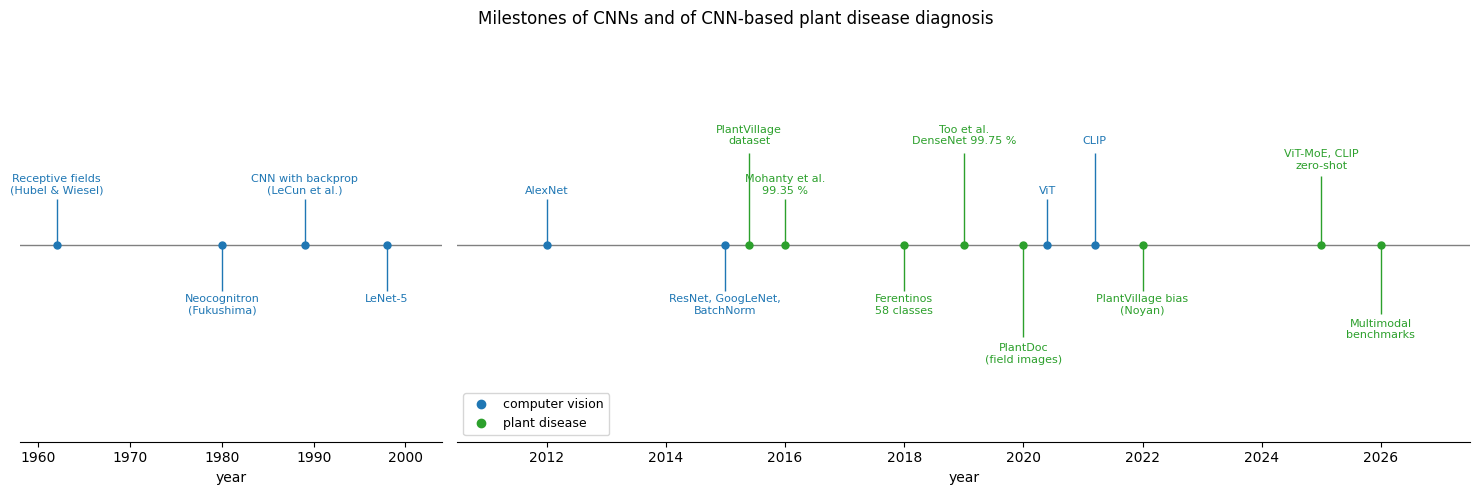

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT_DIR / "results" / "literature_review"
RESULTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_show(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# (year, label, group, height of the label above/below the line)
events = [
    (1962, "Receptive fields\n(Hubel & Wiesel)", "cv", 1.0),
    (1980, "Neocognitron\n(Fukushima)", "cv", -1.0),
    (1989, "CNN with backprop\n(LeCun et al.)", "cv", 1.0),
    (1998, "LeNet-5", "cv", -1.0),
    (2012, "AlexNet", "cv", 1.0),
    (2015, "ResNet, GoogLeNet,\nBatchNorm", "cv", -1.0),
    (2015.4, "PlantVillage\ndataset", "pl", 2.0),
    (2016, "Mohanty et al.\n99.35 %", "pl", 1.0),
    (2018, "Ferentinos\n58 classes", "pl", -1.0),
    (2019, "Too et al.\nDenseNet 99.75 %", "pl", 2.0),
    (2020, "PlantDoc\n(field images)", "pl", -2.0),
    (2020.4, "ViT", "cv", 1.0),
    (2021.2, "CLIP", "cv", 2.0),
    (2022, "PlantVillage bias\n(Noyan)", "pl", -1.0),
    (2025, "ViT-MoE, CLIP\nzero-shot", "pl", 1.5),
    (2026, "Multimodal\nbenchmarks", "pl", -1.5),
]
colour = {"cv": "tab:blue", "pl": "tab:green"}

# two panels: old history (compressed) and recent years (stretched)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2.4]})
for ax, (lo, hi) in zip(axes, [(1958, 2004), (2010.5, 2027.5)]):
    ax.axhline(0, color="gray", lw=1)
    for year, label, grp, h in events:
        if lo <= year <= hi:
            ax.vlines(year, 0, h * 0.75, color=colour[grp], lw=1)
            ax.plot(year, 0, "o", color=colour[grp], ms=5)
            ax.text(year, h * 0.8, label, ha="center", va="bottom" if h > 0 else "top", fontsize=8, color=colour[grp])
    ax.set_xlim(lo, hi); ax.set_ylim(-3.2, 3.2)
    ax.set_yticks([]); ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("year")
axes[1].plot([], [], "o", color="tab:blue", label="computer vision")
axes[1].plot([], [], "o", color="tab:green", label="plant disease")
axes[1].legend(loc="lower left", fontsize=9)
fig.suptitle("Milestones of CNNs and of CNN-based plant disease diagnosis")
save_show("timeline")

## Section 3 - Prior Work on CNN-Based Plant Disease Classification

The table collects the key studies reviewed. Every value was taken from the cited paper's abstract or results, and the **protocols differ** (different class sets, splits and test conditions), so the numbers should be read as evidence of trends rather than as a ranking. The first block shows studies that test on PlantVillage-style images, the second block studies of robustness and bias, and the third block recent multimodal work.

In [2]:
lit = pd.DataFrame([
    # year, reference, method, data, reported result, why it matters here
    (2016, "Mohanty et al.", "AlexNet, GoogLeNet; scratch vs transfer learning", "PlantVillage, 54,306 images, 38 classes",
     "99.35 % accuracy (best); about 31 % on images from other sources", "Baseline that this project extends; shows the lab-to-field drop"),
    (2018, "Ferentinos", "Several CNN architectures", "87,848 images, 25 plants, 58 classes",
     "99.53 % best success rate", "Larger class set, same lab-style data"),
    (2019, "Too et al.", "Fine-tuned VGG16, Inception V4, ResNet 50/101/152, DenseNet-121", "PlantVillage, 38 classes",
     "99.75 % (DenseNet-121)", "Transfer learning; denser networks need fewer parameters"),
    (2022, "Andrew et al.", "Fine-tuned DenseNet-121, ResNet-50, VGG-16, Inception V4", "PlantVillage, 38 classes",
     "99.81 % (DenseNet-121)", "Shows that PlantVillage accuracy is saturated"),
    (2020, "Singh et al. (PlantDoc)", "Classification benchmarks on a new field dataset", "2,598 images, 13 species, 27 classes (internet images)",
     "Training with PlantDoc improves accuracy by up to 31 %", "First public non-laboratory dataset for this task"),
    (2022, "Noyan", "Random forest on only 8 background pixels", "PlantVillage",
     "49.0 % accuracy vs 2.6 % by chance", "Dataset bias: labels are predictable without the leaf"),
    (2025, "Salman et al.", "ViT backbone + mixture of experts", "Train PlantVillage subset (200/class), test PlantDoc",
     "68 % vs 48 % for ViT-Base, 41 % InceptionV3, 43 % EfficientNet", "Transformers improve robustness to field images"),
    (2025, "Benabbas et al.", "CNNs vs ViTs vs CLIP zero-shot", "PlantVillage vs field images",
     "CNNs weak under domain shift; ViTs better; CLIP works from text descriptions", "Supports use of text descriptions"),
    (2026, "Nguyen Quoc et al. (LeafNet)", "Vision-language models, VQA benchmark", "186,000 images with expert metadata and descriptions",
     "Healthy vs diseased above 90 %; pathogen and species below 65 %", "Image + text + metadata dataset like ours"),
    (2026, "Truong et al. (TomaMMU)", "14 vision-language models; fine-tuning", "Tomato leaf multimodal dataset",
     "Fine-tuning raises hard multiple-choice accuracy to 96.09 %", "Multimodal benchmark for tomato, a crop in our data"),
], columns=["year", "reference", "method", "data", "reported result", "relevance to this project"])

lit.to_csv(RESULTS / "literature_table.csv", index=False)
pd.set_option("display.max_colwidth", 80)
display(lit)

,year,reference,method,data,reported result,relevance to this project
0,2016,Mohanty et al.,"AlexNet, GoogLeNet; scratch vs transfer learning","PlantVillage, 54,306 images, 38 classes",99.35 % accuracy (best); about 31 % on images from other sources,Baseline that this project extends; shows the lab-to-field drop
1,2018,Ferentinos,Several CNN architectures,"87,848 images, 25 plants, 58 classes",99.53 % best success rate,"Larger class set, same lab-style data"
2,2019,Too et al.,"Fine-tuned VGG16, Inception V4, ResNet 50/101/152, DenseNet-121","PlantVillage, 38 classes",99.75 % (DenseNet-121),Transfer learning; denser networks need fewer parameters
3,2022,Andrew et al.,"Fine-tuned DenseNet-121, ResNet-50, VGG-16, Inception V4","PlantVillage, 38 classes",99.81 % (DenseNet-121),Shows that PlantVillage accuracy is saturated
4,2020,Singh et al. (PlantDoc),Classification benchmarks on a new field dataset,"2,598 images, 13 species, 27 classes (internet images)",Training with PlantDoc improves accuracy by up to 31 %,First public non-laboratory dataset for this task
5,2022,Noyan,Random forest on only 8 background pixels,PlantVillage,49.0 % accuracy vs 2.6 % by chance,Dataset bias: labels are predictable without the leaf
6,2025,Salman et al.,ViT backbone + mixture of experts,"Train PlantVillage subset (200/class), test PlantDoc","68 % vs 48 % for ViT-Base, 41 % InceptionV3, 43 % EfficientNet",Transformers improve robustness to field images
7,2025,Benabbas et al.,CNNs vs ViTs vs CLIP zero-shot,PlantVillage vs field images,CNNs weak under domain shift; ViTs better; CLIP works from text descriptions,Supports use of text descriptions
8,2026,Nguyen Quoc et al. (LeafNet),"Vision-language models, VQA benchmark","186,000 images with expert metadata and descriptions",Healthy vs diseased above 90 %; pathogen and species below 65 %,Image + text + metadata dataset like ours
9,2026,Truong et al. (TomaMMU),14 vision-language models; fine-tuning,Tomato leaf multimodal dataset,Fine-tuning raises hard multiple-choice accuracy to 96.09 %,"Multimodal benchmark for tomato, a crop in our data"


**Reading the table.** Three patterns stand out.

* **Saturation:** accuracy on PlantVillage reaches 99.35 - 99.81 % for many different networks, so the differences between models are tiny, and a good evaluation needs more than a single accuracy figure (macro-F1, per-class results and a statistical test).
* **A large gap between laboratory and field:** the same models lose most of their accuracy outside PlantVillage. Mohanty et al. (2016) themselves reported only about 31 % on images from other sources, against 2.6 % for random guessing among 38 classes.
* **Movement towards transformers and multimodal models:** the most recent studies compare CNNs with ViTs and vision-language models and add text and metadata to the images.

The chart below shows the lab-to-field gap with the numbers reported by two studies (both are quoted from the papers; the lab and field values of Salman et al. come from separate experiments, as noted).

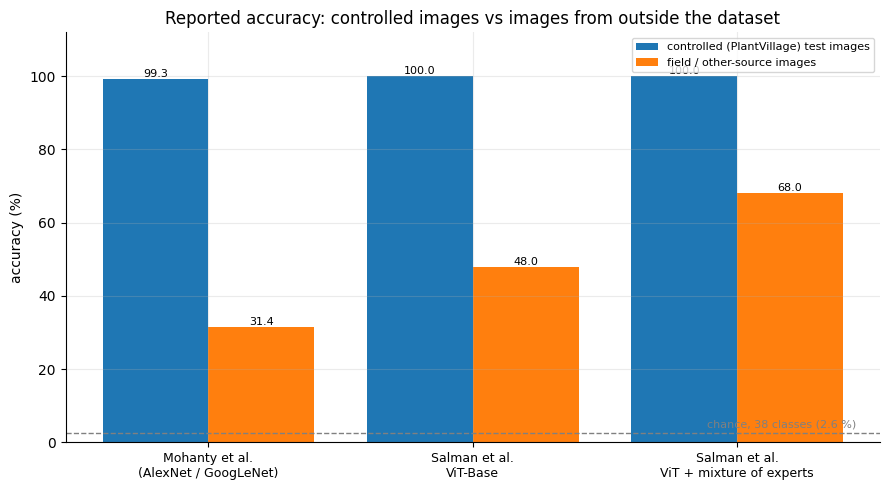

In [3]:
labels = ["Mohanty et al.\n(AlexNet / GoogLeNet)", "Salman et al.\nViT-Base", "Salman et al.\nViT + mixture of experts"]
lab = [99.35, 99.95, 99.96]          # accuracy on PlantVillage-style test images
field = [31.40, 48.0, 68.0]          # accuracy on images from outside PlantVillage
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - 0.2, lab, 0.4, label="controlled (PlantVillage) test images", color="tab:blue")
b2 = ax.bar(x + 0.2, field, 0.4, label="field / other-source images", color="tab:orange")
ax.bar_label(b1, fmt="%.1f", fontsize=8); ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.axhline(2.6, color="gray", ls="--", lw=1)
ax.text(2.45, 4, "chance, 38 classes (2.6 %)", ha="right", fontsize=8, color="gray")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 112)
ax.set_title("Reported accuracy: controlled images vs images from outside the dataset")
ax.legend(loc="upper right", fontsize=8)
save_show("lab_vs_field")

*Notes on the chart.* Mohanty et al. report 31.40 % and 31.69 % on their two small field datasets; the first value is shown. For Salman et al. the controlled value is from the PlantVillage 80:10:10 experiment, and the field value is from training on a 200-images-per-class PlantVillage subset and testing on PlantDoc. The studies use different networks and data, so the chart shows a common pattern, not a comparison between the studies.

## Section 4 - Research Gap

The reviewed work leaves the following gaps. Each one is stated together with its evidence and with how this project relates to it.

**Gap 1 - Generalisation from laboratory to field images.** Models reaching 99 % on PlantVillage lose most of their accuracy on images taken under other conditions (Mohanty et al., 2016; Singh et al., 2020; Salman et al., 2025; Benabbas et al., 2025). Differences in lighting, background, resolution, camera distance and disease severity all contribute (Picon et al., 2019, as discussed by Salman et al., 2025). Closing this gap is still an open problem. *This project does not solve it, but it measures the problem honestly and discusses it as a limitation.*

**Gap 2 - Dataset bias and shortcut learning.** Noyan (2022) showed that a classifier trained on only 8 background pixels per image reaches 49.0 % accuracy, so PlantVillage labels are partly predictable from capture conditions rather than from the leaf. This is an instance of *shortcut learning*, where a network uses easy but irrelevant cues (Geirhos et al., 2020). *High accuracy on a random PlantVillage split therefore overstates real performance, and conclusions must be drawn with this in mind.*

**Gap 3 - Saturated benchmarks and thin evaluation.** With accuracies of 99.35 - 99.96 % across many models, small differences are hard to interpret. Class imbalance also affects the results: Salman et al. (2025) note that tomato images make up 43.4 % of PlantVillage. *This project reports macro-averaged metrics, per-class results and a statistical test, and analyses class imbalance explicitly.*

**Gap 4 - Leakage between training and test images.** Several photographs in PlantVillage show the same physical leaf. Mohanty et al. (2016) kept all images of a leaf in the same split where leaf identifiers were available, but a plain random split does not guarantee this. *This is recorded as a limitation of our stratified random split.*

**Gap 5 - Image-only models.** Most CNN studies use the image alone. Multimodal image-text datasets and vision-language benchmarks have only appeared recently (Nguyen Quoc et al., 2026; Truong et al., 2026) and focus on large pretrained vision-language models. Compact models trained from scratch that make use of text descriptions and metadata are little studied. *This project builds a multi-modal version of the dataset and uses text as class descriptions.*

**Gap 6 - Efficiency and deployment.** The strongest field-robust models are large and complex; for example the mixture-of-experts model needs extra computation at prediction time (Salman et al., 2025). Small, cheap networks that run on a phone are attractive for farmers, but their accuracy-versus-cost trade-off is rarely reported together. *This project reports parameters, operations and prediction time alongside accuracy.*

**Gap 7 - Single leaf, single disease.** Common datasets show one leaf with one disease on a plain background, while real photographs can contain several leaves (Singh et al., 2020), and some PlantDoc images show several diseases at once (Salman et al., 2025). This is also the point where object detection (Section 7.5) becomes necessary.

## Section 5 - Novelty of the Chosen Method Compared with Prior Work

It is important to be precise about what is new. **The CNN itself is not new**: stacked convolution, pooling and fully connected layers follow the line from LeNet to AlexNet, and Mohanty et al. (2016) applied that design to the same dataset. Claiming otherwise would be wrong. The contribution of this project lies in how the method is designed, compared and evaluated.

**1. A broader, controlled comparison on identical data.** Mohanty et al. compared two CNN architectures and training from scratch against transfer learning. This project compares **three paradigms on the same train/validation/test split**: a custom CNN trained from scratch, classical classifiers (SVM, random forest) on hand-crafted features (colour histograms, HOG) and on deep features, and a transfer-learned ResNet18. Comparing hand-crafted and deep features with the same classifier separates the effect of the *features* from the effect of the *classifier*.

**2. A multi-modal version of the data.** Each image is paired with a symptom description and metadata (crop, cause type, pathogen), the same kind of information used in recent multimodal plant-disease datasets such as LeafNet (Nguyen Quoc et al., 2026). The text is used as a *class description* and not as a hidden input, to avoid label leakage. Compared with large vision-language benchmarks, the data here is small and class-level, so it supports a proof of concept rather than a new benchmark.

**3. A small custom architecture with explicit design choices.** Batch normalisation after every convolution and an adaptive average pool before the classifier reduce the first fully connected layer from about 16.8 million to about 1 million weights. The network has about 1.4 million parameters in total, much fewer than AlexNet (about 60 million, as noted by Mohanty et al., 2016), which makes it suitable for deployment on a phone.

**4. A more demanding evaluation protocol.** Beyond accuracy, the project analyses class imbalance and uses macro-F1, per-class metrics, confusion matrices, a complexity analysis (parameters, multiply-accumulate operations and memory) and a statistical test of the differences between models.

**What is not claimed.** This project does not claim state-of-the-art accuracy, and it does not solve the lab-to-field gap or the dataset bias described in Section 4. Its value is a transparent, reproducible comparison with an honest discussion of limits.

| Aspect | Prior work reviewed | This project |
|---|---|---|
| Models compared | Typically a few CNN architectures | Custom CNN, SVM and random forest (hand-crafted and deep features), ResNet18 |
| Data modality | Images (mostly) | Images, text descriptions and metadata |
| Evaluation | Accuracy, often also F1 | Macro metrics, per-class results, complexity and a statistical test |
| Model size reported | Rarely alongside accuracy | Parameters, operations and prediction time |
| Field robustness | Studied by recent work | Discussed as a limitation, not solved |

## Section 6 - Potential Drawbacks of the Chosen Method

The table analyses the weaknesses of a from-scratch CNN, with the evidence from the literature and the mitigation used in this project.

| Drawback | Evidence | Mitigation in this project |
|---|---|---|
| **Needs a lot of labelled data** and learns nothing from other tasks when trained from scratch | Transfer learning gives better results in Mohanty et al. (2016) and is the basis of the best results of Too et al. (2019) | ResNet18 transfer learning is included as a benchmark to measure the difference |
| **Limited global context**: convolutions look at local regions, so relations between distant parts of a leaf are captured only in deep layers | ViTs generalise better to field images (Benabbas et al., 2025; Salman et al., 2025) | Discussed as a limitation; a transformer is outside the scope but is named as future work |
| **Shortcut learning and dataset bias** | 49.0 % accuracy from 8 background pixels (Noyan, 2022); shortcut learning (Geirhos et al., 2020) | Data augmentation, honest reporting of the limitation, no claim of field performance |
| **Poor robustness to domain shift** | About 31 % on field images (Mohanty et al., 2016); CNNs described as having limited robustness (Benabbas et al., 2025) | Not solved; stated as a limitation |
| **Sensitivity to class imbalance** | Tomato forms 43.4 % of PlantVillage (Salman et al., 2025) | Stratified split, macro-F1, optional class-weighted loss |
| **Black-box behaviour**: predictions are hard to explain | General property of deep networks | Filter and feature-map visualisation, t-SNE of the learned features |
| **Overfitting** | Always a risk with a small dataset per class | Dropout, weight decay, augmentation, early stopping, learning curves |
| **Training cost and many hyper-parameters** | Hours of training on a GPU cluster in the original study (Mohanty et al., 2016) | Small network, few epochs, complexity analysis |
| **Single label per image** | Some field images show several diseases at once (Salman et al., 2025) | Stated as a limitation; detection is named as an extension |
| **Subtle early-stage symptoms** are hard to recognise | Disease stage affects accuracy (Picon et al., 2019, as discussed by Salman et al., 2025) | Not addressed |

## Section 7 - State of the Art

### 7.1 Controlled benchmarks are saturated

On PlantVillage, fine-tuned CNNs reach 99.75 % (DenseNet-121, Too et al., 2019) and 99.81 % (DenseNet-121, Andrew et al., 2022). A recent transformer-based model reports 99.96 % on a PlantVillage 80:10:10 split, and the strongest plain ViT and several fine-grained models are within a few hundredths of a percent of it (Salman et al., 2025). On this benchmark, further gains are essentially measurement noise, so the research frontier has moved to robustness and multimodality.

### 7.2 Robustness to field images: transformers and mixtures of experts

Models built for the field-condition setting combine a **Vision Transformer** backbone with extra components. Salman et al. (2025) add a **mixture of experts** with entropy, orthogonality and usage regularisation. Trained on a balanced PlantVillage subset and tested on PlantDoc, their model reaches 68 % accuracy against 48 % for ViT-Base, 41 % for InceptionV3 and 43 % for EfficientNet. The result shows both the progress and the remaining gap: even the best result is far from the 99 % seen in the laboratory. The authors also note that the mixture of experts adds computation at prediction time.

### 7.3 Zero-shot and vision-language approaches

Benabbas et al. (2025) compared CNNs, Vision Transformers and CLIP-based zero-shot models on the gap between PlantVillage and field images. They found limited robustness for CNNs under domain shift, stronger generalisation for ViTs, and strong adaptability and interpretability for CLIP models, which classify diseases from natural-language descriptions without task-specific training. This is the direction in which the text descriptions of our multi-modal dataset can be used later (for example, matching an image embedding to the embedding of the class description).

### 7.4 Multimodal datasets and benchmarks (2025 - 2026)

Large multimodal resources have appeared very recently. **LeafNet** (Nguyen Quoc et al., 2026) contains 186,000 leaf images with expert-annotated metadata and a visual question answering benchmark, **LeafBench**, for vision-language models. Its results show that models do well on the coarse question of healthy versus diseased (above 90 % accuracy) but find fine-grained pathogen and species identification much harder (below 65 %). **TomaMMU** (Truong et al., 2026) provides a multimodal understanding benchmark for tomato leaf diseases, finds that 14 recent vision-language models perform poorly on challenging questions, and shows that fine-tuning raises multiple-choice accuracy to 96.09 %. Both papers argue that image-only classification is not enough and that text and metadata are needed for diagnosis and reasoning. Our dataset, built from images, symptom text and pathogen metadata, is a small-scale example of the same structure.

### 7.5 From classification to object detection

Classification assigns one label to an image. **Object detection** finds and labels several objects in an image with bounding boxes, which matters when one plant shows several lesions or diseases. Detection with CNNs follows two lines: two-stage detectors such as R-CNN (Girshick et al., 2014) and its faster successors (Ren et al., 2015), which favour localisation accuracy, and one-stage detectors such as YOLO (Redmon et al., 2016), which favour speed. PlantDoc (Singh et al., 2020) also provides annotations for detection of diseases in field images. Detection is outside the scope of this project, which classifies single leaves, but the same CNN ideas carry over, and it is the natural extension for real farm images.

### 7.6 Where this project sits

The project uses established, well-understood components (CNN, SVM and random forest on hand-crafted features, transfer learning with ResNet) on the standard PlantVillage data, extended with text and metadata. It does not reach the state of the art in robustness, which is held by transformer, mixture-of-experts and vision-language models, and it makes no such claim. It does contribute a clear and reproducible comparison and an honest account of limitations, in line with the gaps identified in Section 4.

## Section 8 - Summary: What the Review Means for the Project

The last cell turns the findings of the review into concrete design decisions, so the project is visibly shaped by the literature.

In [4]:
decisions = pd.DataFrame([
    ("Accuracy on PlantVillage is saturated (99.35 - 99.96 %)", "Report macro precision, recall and F1, per-class results and a statistical test, not accuracy alone"),
    ("Strong class imbalance (tomato 43.4 % of images)", "Stratified split, macro-averaged metrics, optional class-weighted loss"),
    ("Dataset bias and shortcut learning (Noyan, 2022)", "Strong augmentation; state clearly that results do not transfer to field images"),
    ("Same leaf appears in several images", "Note the possible train/test leakage as a limitation"),
    ("Transfer learning beats training from scratch (Mohanty et al., 2016)", "Include ResNet18 transfer learning as a benchmark"),
    ("Hand-crafted features were the pre-deep-learning approach", "Include SVM and random forest on colour histogram and HOG features"),
    ("Transformers and CLIP generalise better to field images", "Name as future work; keep text descriptions as class prototypes for later image-text matching"),
    ("Multimodal image-text data is the current direction (2026)", "Build the multi-modal dataset (image, symptom text, metadata)"),
    ("Deployment on phones matters for farmers", "Report parameters, operations and prediction time of every model"),
], columns=["finding from the literature", "decision in this project"])
decisions.to_csv(RESULTS / "design_decisions.csv", index=False)
pd.set_option("display.max_colwidth", 120)
display(decisions)

,finding from the literature,decision in this project
0,Accuracy on PlantVillage is saturated (99.35 - 99.96 %),"Report macro precision, recall and F1, per-class results and a statistical test, not accuracy alone"
1,Strong class imbalance (tomato 43.4 % of images),"Stratified split, macro-averaged metrics, optional class-weighted loss"
2,"Dataset bias and shortcut learning (Noyan, 2022)",Strong augmentation; state clearly that results do not transfer to field images
3,Same leaf appears in several images,Note the possible train/test leakage as a limitation
4,"Transfer learning beats training from scratch (Mohanty et al., 2016)",Include ResNet18 transfer learning as a benchmark
5,Hand-crafted features were the pre-deep-learning approach,Include SVM and random forest on colour histogram and HOG features
6,Transformers and CLIP generalise better to field images,Name as future work; keep text descriptions as class prototypes for later image-text matching
7,Multimodal image-text data is the current direction (2026),"Build the multi-modal dataset (image, symptom text, metadata)"
8,Deployment on phones matters for farmers,"Report parameters, operations and prediction time of every model"


## References

Andrew, J., Eunice, J., Popescu, D. E., Chowdary, M. K. & Hemanth, J. 2022, Deep learning-based leaf disease detection in crops using images for agricultural applications, *Agronomy*, vol. 12, no. 10, article 2395, <https://doi.org/10.3390/agronomy12102395>.

Benabbas, W., Brahimi, M., Akhrouf, S. & Fortas, B. 2025, Rethinking plant disease diagnosis: bridging the academic-practical gap with vision transformers and zero-shot learning, arXiv:2511.18989.

Dosovitskiy, A., Beyer, L., Kolesnikov, A. et al. 2021, An image is worth 16x16 words: transformers for image recognition at scale, *International Conference on Learning Representations*, arXiv:2010.11929.

Ferentinos, K. P. 2018, Deep learning models for plant disease detection and diagnosis, *Computers and Electronics in Agriculture*, vol. 145, pp. 311-318, <https://doi.org/10.1016/j.compag.2018.01.009>.

Fukushima, K. 1980, Neocognitron: a self-organizing neural network model for a mechanism of pattern recognition unaffected by shift in position, *Biological Cybernetics*, vol. 36, pp. 193-202.

Geirhos, R., Jacobsen, J.-H., Michaelis, C. et al. 2020, Shortcut learning in deep neural networks, *Nature Machine Intelligence*, vol. 2, pp. 665-673.

Girshick, R., Donahue, J., Darrell, T. & Malik, J. 2014, Rich feature hierarchies for accurate object detection and semantic segmentation, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 580-587.

He, K., Zhang, X., Ren, S. & Sun, J. 2016, Deep residual learning for image recognition, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 770-778.

Howard, A. G., Zhu, M., Chen, B. et al. 2017, MobileNets: efficient convolutional neural networks for mobile vision applications, arXiv:1704.04861.

Huang, G., Liu, Z., van der Maaten, L. & Weinberger, K. Q. 2017, Densely connected convolutional networks, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 4700-4708.

Hubel, D. H. & Wiesel, T. N. 1962, Receptive fields, binocular interaction and functional architecture in the cat's visual cortex, *The Journal of Physiology*, vol. 160, no. 1, pp. 106-154.

Hughes, D. P. & Salathe, M. 2015, An open access repository of images on plant health to enable the development of mobile disease diagnostics, arXiv:1511.08060.

Ioffe, S. & Szegedy, C. 2015, Batch normalization: accelerating deep network training by reducing internal covariate shift, *Proceedings of the 32nd International Conference on Machine Learning*, pp. 448-456.

Kamilaris, A. & Prenafeta-Boldu, F. X. 2018, Deep learning in agriculture: a survey, *Computers and Electronics in Agriculture*, vol. 147, pp. 70-90, <https://doi.org/10.1016/j.compag.2018.02.016>.

Kingma, D. P. & Ba, J. 2015, Adam: a method for stochastic optimization, *International Conference on Learning Representations*, arXiv:1412.6980.

Krizhevsky, A., Sutskever, I. & Hinton, G. E. 2012, ImageNet classification with deep convolutional neural networks, *Advances in Neural Information Processing Systems*, vol. 25, pp. 1097-1105.

LeCun, Y., Boser, B., Denker, J. S. et al. 1989, Backpropagation applied to handwritten zip code recognition, *Neural Computation*, vol. 1, pp. 541-551.

LeCun, Y., Bottou, L., Bengio, Y. & Haffner, P. 1998, Gradient-based learning applied to document recognition, *Proceedings of the IEEE*, vol. 86, no. 11, pp. 2278-2324.

Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T. & Xie, S. 2022, A ConvNet for the 2020s, *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition*, pp. 11976-11986.

Mohanty, S. P., Hughes, D. P. & Salathe, M. 2016, Using deep learning for image-based plant disease detection, *Frontiers in Plant Science*, vol. 7, article 1419, <https://doi.org/10.3389/fpls.2016.01419>.

Nguyen Quoc, K., Dao, P. D. & Quach, L.-D. 2026, LeafNet: a large-scale dataset and comprehensive benchmark for foundational vision-language understanding of plant diseases, arXiv:2602.13662.

Noyan, M. A. 2022, Uncovering bias in the PlantVillage dataset, arXiv:2206.04374, <https://doi.org/10.48550/arXiv.2206.04374>.

Picon, A., Alvarez-Gila, A., Seitz, M., Ortiz-Barredo, A., Echazarra, J. & Johannes, A. 2019, Deep convolutional neural networks for mobile capture device-based crop disease classification in the wild, *Computers and Electronics in Agriculture*, vol. 161, pp. 280-290, <https://doi.org/10.1016/j.compag.2018.04.002>.

Radford, A., Kim, J. W., Hallacy, C. et al. 2021, Learning transferable visual models from natural language supervision, *Proceedings of the 38th International Conference on Machine Learning*, PMLR 139, pp. 8748-8763.

Redmon, J., Divvala, S., Girshick, R. & Farhadi, A. 2016, You only look once: unified, real-time object detection, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 779-788.

Ren, S., He, K., Girshick, R. & Sun, J. 2015, Faster R-CNN: towards real-time object detection with region proposal networks, *Advances in Neural Information Processing Systems*, vol. 28.

Russakovsky, O., Deng, J., Su, H. et al. 2015, ImageNet large scale visual recognition challenge, *International Journal of Computer Vision*, vol. 115, pp. 211-252.

Salman, Z., Muhammad, A. & Han, D. 2025, Plant disease classification in the wild using vision transformers and mixture of experts, *Frontiers in Plant Science*, vol. 16, article 1522985, <https://doi.org/10.3389/fpls.2025.1522985>.

Simonyan, K. & Zisserman, A. 2014, Very deep convolutional networks for large-scale image recognition, arXiv:1409.1556.

Singh, D., Jain, N., Jain, P., Kayal, P., Kumawat, S. & Batra, N. 2020, PlantDoc: a dataset for visual plant disease detection, *Proceedings of the 7th ACM IKDD CoDS and 25th COMAD*, pp. 249-253, <https://doi.org/10.1145/3371158.3371196>.

Sladojevic, S., Arsenovic, M., Anderla, A., Culibrk, D. & Stefanovic, D. 2016, Deep neural networks based recognition of plant diseases by leaf image classification, *Computational Intelligence and Neuroscience*, vol. 2016, article 3289801, <https://doi.org/10.1155/2016/3289801>.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. & Salakhutdinov, R. 2014, Dropout: a simple way to prevent neural networks from overfitting, *Journal of Machine Learning Research*, vol. 15, pp. 1929-1958.

Szegedy, C., Liu, W., Jia, Y. et al. 2015, Going deeper with convolutions, *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 1-9.

Tan, M. & Le, Q. 2019, EfficientNet: rethinking model scaling for convolutional neural networks, *Proceedings of the 36th International Conference on Machine Learning*, pp. 6105-6114.

Too, E. C., Yujian, L., Njuki, S. & Yingchun, L. 2019, A comparative study of fine-tuning deep learning models for plant disease identification, *Computers and Electronics in Agriculture*, vol. 161, pp. 272-279, <https://doi.org/10.1016/j.compag.2018.03.032>.

Truong, G.-H., Nguyen Quoc, K. & Quach, L.-D. 2026, TomaMMU: a comprehensive multimodal understanding benchmark for tomato leaf diseases, arXiv:2608.08727.